In [1]:
import pandas as pd
import os
import smarts_cerebellum.globals as gl
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import numpy as np

# DTI metrics
dti = pd.read_csv(os.path.join(gl.baseDir, 'MNISymC_FaMap', 'summary_MNISymC_CST_FaMap.tsv'), sep = '\t')
dti = dti[dti.regionname == 'CST_R']
dti = dti[dti.isPatient == 1]

# cerebellum GMV
cerebel = pd.read_csv(os.path.join(gl.baseDir, 'MNISymC_GM', 'summary_MNISymC_Nettekoven_2024_GM_mod.tsv'), sep = '\t')
cerebel = cerebel[cerebel.isPatient==1] # just patients

cerebel['hemisphere'] = cerebel.regionname.str[2]
cerebel['regionname_bilat'] = cerebel.regionname.str[:2]

cerebel_wide = cerebel.pivot(index = ['subj_id', 'Week', 'regionname_bilat'], columns = 'hemisphere', values = 'mean')
cerebel_wide['left_norm'] = cerebel_wide['L']/cerebel_wide['R']
cerebel_wide = cerebel_wide.reset_index()
cerebel = cerebel_wide.melt(
    id_vars = ['subj_id', 'Week', 'regionname_bilat'],
    value_vars = ['L', 'R', 'left_norm'],
    var_name = 'metric_cerebel', value_name = 'mean_cerebel'
)
cerebel = cerebel[cerebel.metric_cerebel == 'left_norm']
cerebel = cerebel.drop(columns = 'metric_cerebel')
cerebel = cerebel.rename(columns = {'mean_cerebel': 'left_norm'})

# behavioural metrics
behav = pd.read_csv(os.path.join(gl.baseDir, 'behavioural', 'summary_paretic.dat'), sep = '\t')
behav.rename(columns = {'subj_name': 'subj_id', 'week': 'Week'}, inplace = True)
behav['subj_id'] = behav['subj_id'].str.strip()
behav.loc[behav['Week']==1, 'Week'] = 0


# Asymmetry index (FA)
ref: Stinear et al., 2019 (https://doi.org/10.1093%2Fbrain%2Fawl333)

In [24]:
# FISHER Z TRANSFORM - INDIVIDUATION
rows_indiv = []
for week in gl.weeks:
    cst_plot = dti[dti.Week == week]
    behav_plot = behav[(behav.Week == week)]
    behav_cst = pd.merge(behav_plot, cst_plot, on = ['subj_id', 'Week'], suffixes = ('_behav', '_cst'))
    
    r_stat, p_val = stats.pearsonr(behav_cst['asymmetry_index'], behav_cst['indiv_norm']) # use fitted value from piecewise function, y_hat

    n = len(behav_cst.subj_id.unique())
    z, se = np.arctanh(r_stat), 1/np.sqrt(n-3)
    lo, hi = np.tanh([z - 1.96*se, z + 1.96*se])
    rows_indiv.append({'Week': week, 'r_stat': r_stat, 'p_val': p_val, 'n': n, 'z': z, 'se': se, 'lo': lo, 'hi': hi})
rdf_indiv = pd.DataFrame(rows_indiv)

In [23]:
# FISHER Z TRANSFORM - STRENGTH
rows_mvc = []
for week in gl.weeks:
    cst_plot = dti[dti.Week == week]
    behav_plot = behav[(behav.Week == week)]
    behav_cst = pd.merge(behav_plot, cst_plot, on = ['subj_id', 'Week'], suffixes = ('_behav', '_cst'))
    
    r_stat, p_val = stats.pearsonr(behav_cst['asymmetry_index'], behav_cst['mvc_norm']) # use fitted value from piecewise function, y_hat

    n = len(behav_cst.subj_id.unique())
    z, se = np.arctanh(r_stat), 1/np.sqrt(n-3)
    lo, hi = np.tanh([z - 1.96*se, z + 1.96*se])
    rows_mvc.append({'Week': week, 'r_stat': r_stat, 'p_val': p_val, 'n': n, 'z': z, 'se': se, 'lo': lo, 'hi': hi})
rdf_mvc = pd.DataFrame(rows_mvc)

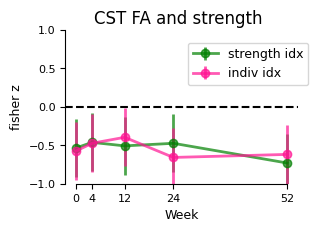

In [31]:
fig, ax = plt.subplots(figsize = (3,2))

ax.errorbar(x = rdf_mvc['Week'], y = rdf_mvc['z'], yerr = se,              
marker = 'o', linestyle = '-', linewidth = 2, color = 'green', alpha = .7, label = 'strength idx')

ax.errorbar(x = rdf_indiv['Week'], y = rdf_indiv['z'], yerr = se,              
marker = 'o', linestyle = '-', linewidth = 2, color = 'deeppink', alpha = .7, label = 'indiv idx')

ax.set_xticks(gl.weeks)
ax.set_xlabel('Week')
ax.set_ylabel('fisher z')
plt.legend(bbox_to_anchor = (.5,.6))
plt.suptitle("CST FA and strength")
ax.set_ylim(-1, 1)
plt.axhline(y = 0, linestyle = '--', color = 'k', linewidth = '1.5')
sns.despine(trim = True)
plt.show()

# cerebellar GMV and CST

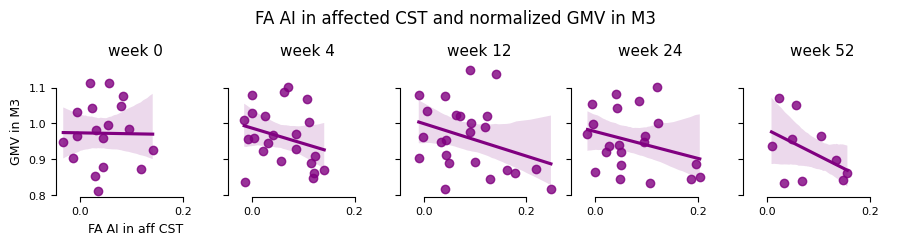

**Pearson R and p-value for FA in affected CST and GMV in M3 (cerebellum)** 

week 0: r = -0.013437140893041585, p-value = 0.9577970778355812
week 4: r = -0.278525139775133, p-value = 0.2094210318539794
week 12: r = -0.3279427237342908, p-value = 0.1177132339024392
week 24: r = -0.2932709422727436, p-value = 0.19696872037415514
week 52: r = -0.4501074179290722, p-value = 0.1917901760933422


In [20]:
fig, axs = plt.subplots(1, 5, figsize = (9,2), sharey = True, sharex = True, constrained_layout = True)
for i, week in enumerate(gl.weeks):
    cerebel_plot = cerebel[(cerebel.Week == week) & (cerebel.regionname_bilat == 'M3')]
    dti_plot = dti[(dti.Week == week)]
    cerebel_dti_plot = pd.merge(dti_plot, cerebel_plot, on = ['subj_id', 'Week'], suffixes = ('_dti', '_cerebel'))

    ax = axs[i]
    sns.regplot(x = 'asymmetry_index', y = 'left_norm', data = cerebel_dti_plot, ax = ax, color = 'purple')

    ax.set_ylabel('')
    ax.set_xlabel('')

    ax.set_title(f'week {week}')
    

axs[0].set_ylabel("GMV in M3")
axs[0].set_xlabel(f"FA AI in aff CST")
fig.suptitle(f"FA AI in affected CST and normalized GMV in M3", y = 1.15)


sns.despine(trim = True)
plt.show()


print("**Pearson R and p-value for FA in affected CST and GMV in M3 (cerebellum)** \n")
for week in gl.weeks:
    cerebel_plot = cerebel[(cerebel.Week == week) & (cerebel.regionname_bilat == 'M3')]
    dti_plot = dti[(dti.Week == week)]
    cerebel_dti_plot = pd.merge(dti_plot, cerebel_plot, on = ['subj_id', 'Week'], suffixes = ('_dti', '_cerebel'))

    r_stat, p_stat = stats.pearsonr(cerebel_dti_plot['asymmetry_index'], cerebel_dti_plot['left_norm'])
    print(f'week {week}: r = {r_stat}, p-value = {p_stat}')

These results look like the ones we have with Jing's dataset, just with fewer subjects; not sure why we don't have all dti (images) tho

/localscratch/tmp/ipykernel_26767/792758167.py:32: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend(loc = 'lower right', frameon = False, fontsize = 8)


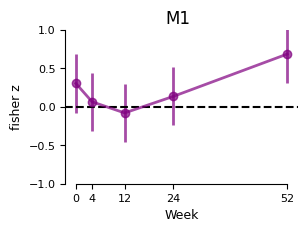

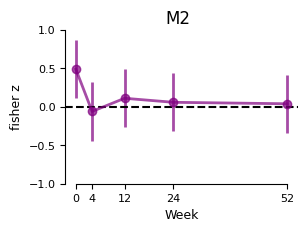

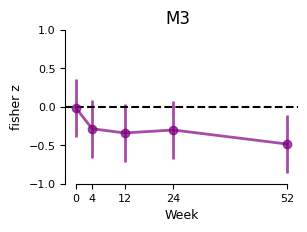

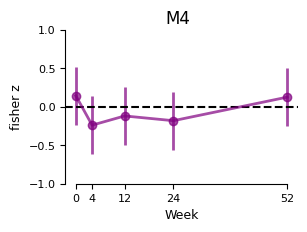

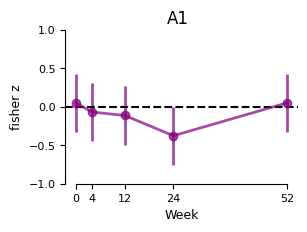

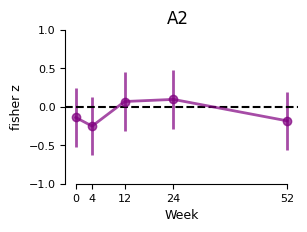

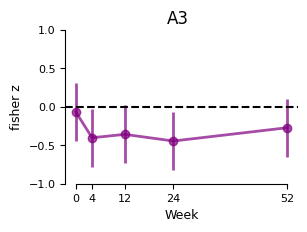

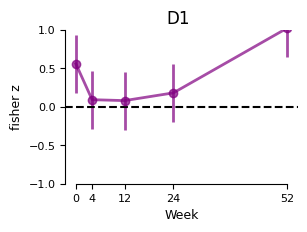

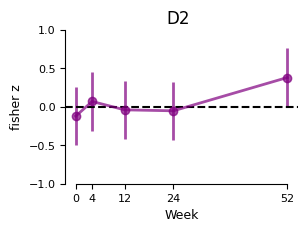

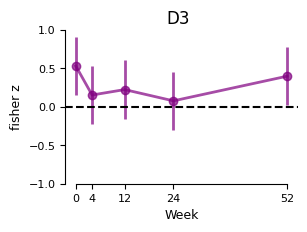

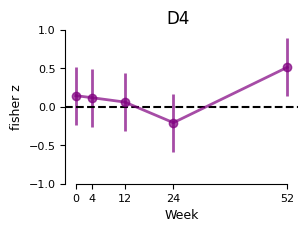

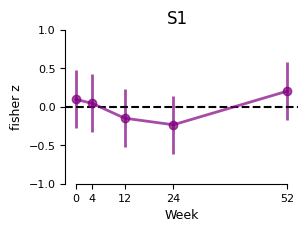

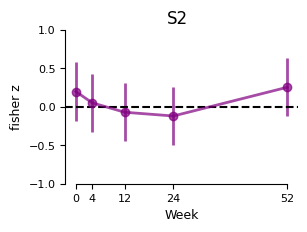

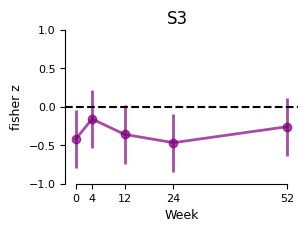

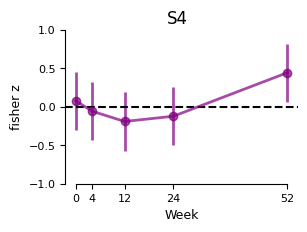

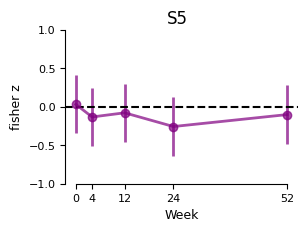

In [16]:
# FISHER Z TRANSFORM
rows = []
for roi in gl.rois['Nettekoven2024']:
    for week in gl.weeks:
        cst_plot = dti[dti.Week == week]
        cerebel_plot = cerebel[(cerebel.Week == week) & (cerebel.regionname_bilat == roi)]
        cerebel_cst = pd.merge(cerebel_plot, cst_plot, on = ['subj_id'], suffixes = ('_cerebel', '_cst'))
        
        r_stat, p_val = stats.pearsonr(cerebel_cst['asymmetry_index'], cerebel_cst['left_norm']) # use fitted value from piecewise function, y_hat

        n = len(cerebel_cst.subj_id.unique())
        z, se = np.arctanh(r_stat), 1/np.sqrt(n-3)
        lo, hi = np.tanh([z - 1.96*se, z + 1.96*se])
        rows.append({'Week': week, 'roi': roi, 'r_stat': r_stat, 'p_val': p_val, 'n': n, 'z': z, 'se': se, 'lo': lo, 'hi': hi})
r_df = pd.DataFrame(rows)

# plot r values for correlations

for roi in gl.rois['Nettekoven2024']:
    fig, ax = plt.subplots(figsize = (3,2))
    
    plotdf = r_df[r_df['roi'] == roi].sort_values('Week')

    ax.errorbar(x = plotdf['Week'], y = plotdf['z'], yerr = se,              
    marker = 'o', linestyle = '-', linewidth = 2, color = 'purple', alpha = .7)

    ax.set_xticks(gl.weeks)
    ax.set_xlabel('Week')
    ax.set_ylabel('fisher z')
    ax.set_ylim(-1, 1)
    plt.axhline(y = 0, linestyle = '--', color = 'k', linewidth = '1.5')
    ax.legend(loc = 'lower right', frameon = False, fontsize = 8)
    fig.suptitle(roi)
    sns.despine(trim = True)
    plt.show()